# Joint MLE with single trials

**Model:** `template(c, a, d) = mu_angle(c, a) × gain(c, d)`
- `mu_angle(c, a)` — RF profile: mean response of cell *c* at position *a*, averaged across distances
- `gain(c, d)` — distance gain: how distance *d* scales cell *c*’s response at its RF peak (mean-normalised)

Distance-invariant cells have flat gain ≈ [1,1,1,1] and drop out of distance decoding naturally.
Primary metric: **Distance MAE** (continuous softmax readout). Secondary: hard-argmax accuracy.

**Structure:**
- **Part 1** — Approach and results for a single session
- **Part 2** — Single-trial plots: after trained how does it do for a single trial
- **Part 3** — Dependency on good cells for performance

In [59]:
import sys
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project\radial-analysis')
from path_setup import setup_project_path
setup_project_path()

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp, softmax
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from src.decoding.SessionAggregator import SessionAggregator
from src.decoding.Decoders import (
    MLE,
    FactoredMLE,
)

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
MOUSE                 = 'SAM041'
EXPERIMENT            = 'tiling_120um'
RANDOM_STATE          = 42
np.random.seed(RANDOM_STATE)

agg = SessionAggregator(
    mouse_name=MOUSE,
    experiment_name=EXPERIMENT
)

[ok] Loaded aggregated traces from cache


---
## Part 1 — Distance Decoding for single trials

### § 1.0 — Angle Decoding, multi-trial, MLE vs FactoredMLE

  Angle MAE:    4.30°
  Angle RMSE:   8.18°
  Correlation:  0.955
  R²:           0.904
  Dist MAE:     0.64 cm
  Dist Acc:     52.1%
  Angle MAE:    10.42°
  Angle RMSE:   22.37°
  Correlation:  0.676
  R²:           0.283
  Dist MAE:     0.94 cm
  Dist Acc:     27.1%


C:\Users\acostamendoza\projects\distance-project\radial-analysis\src\decoding\Decoders.py:1200: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  


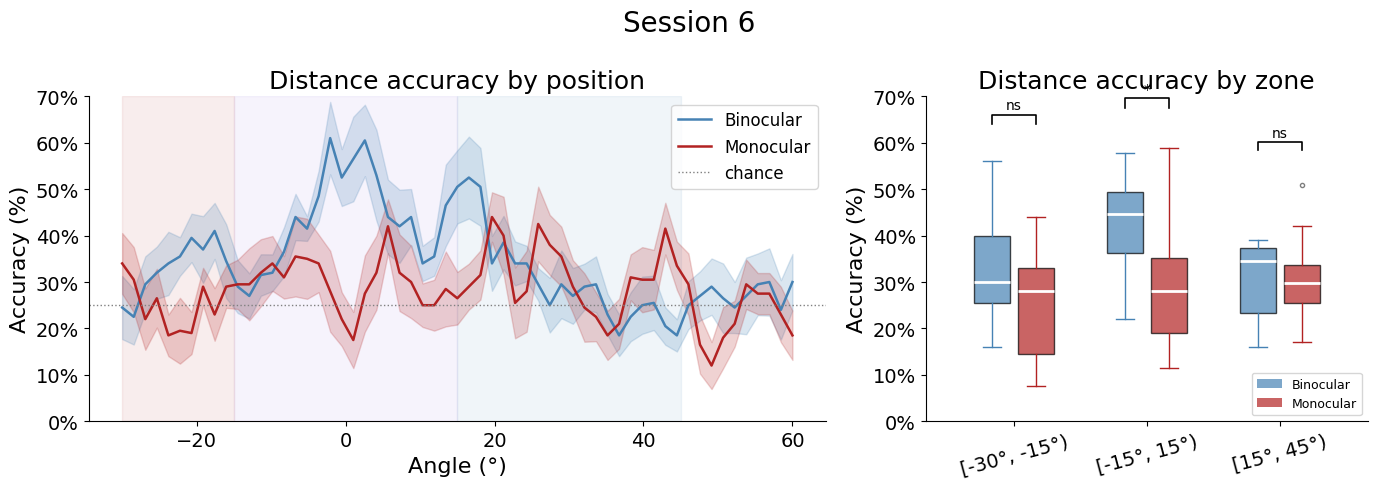

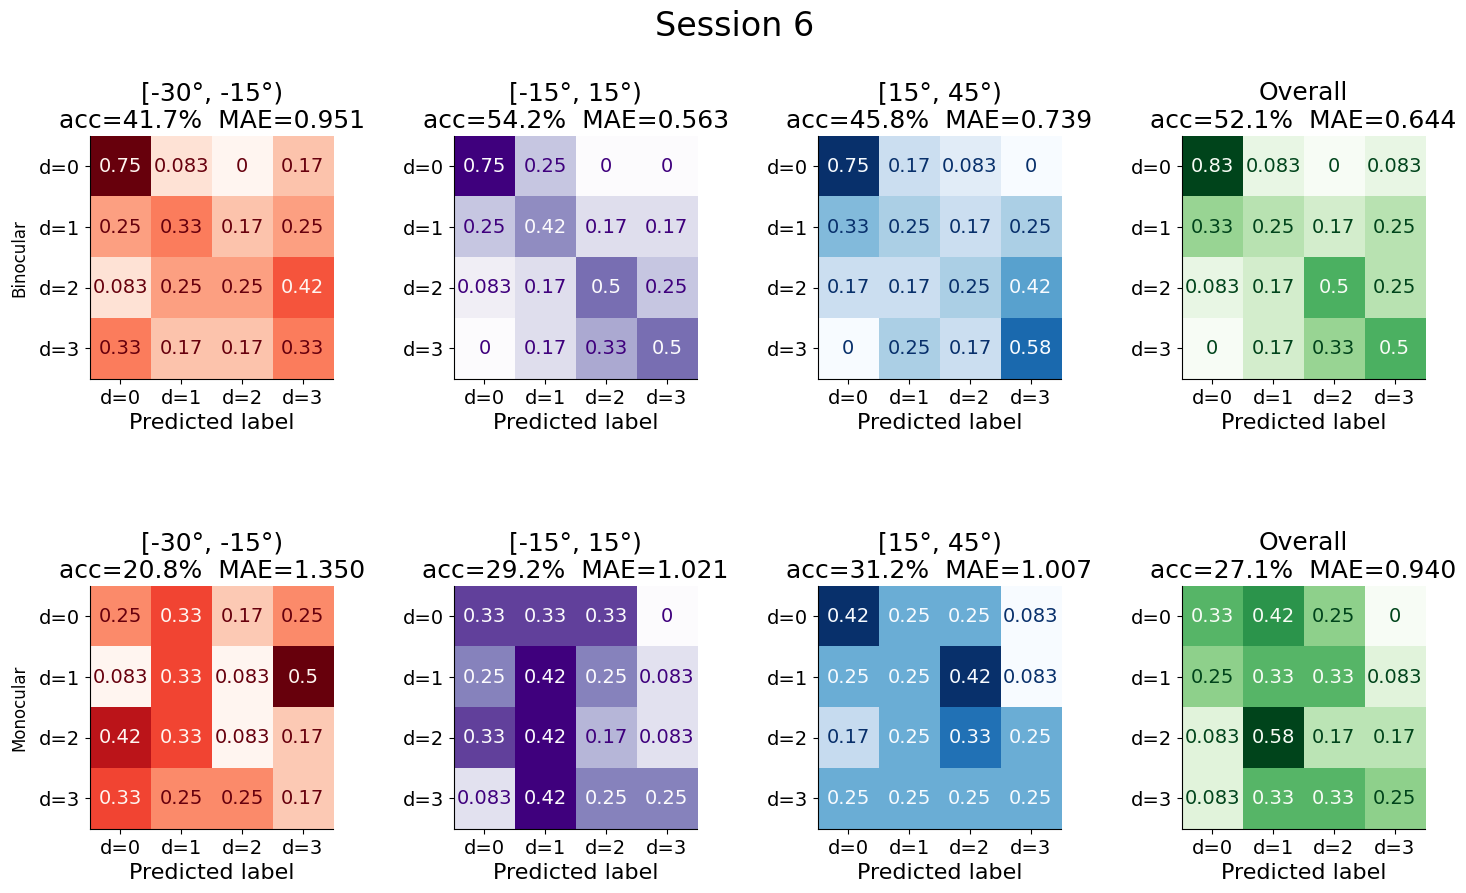

In [ ]:
session_id = 6

binocular_results = FactoredMLE.cross_validate_single_trial(agg, monocular=0, session=session_id, n_folds = 10)
monocular_results = FactoredMLE.cross_validate_single_trial(agg, monocular=1, session=session_id, n_folds = 10)

fig = FactoredMLE.plot_distance_comparison(binocular_results, monocular_results, title=f'Session {session_id}')
fig = FactoredMLE.plot_confusion_by_angle_range([binocular_results, monocular_results], labels=['Binocular', 'Monocular'], title=f'Session {session_id}')

C:\Users\acostamendoza\projects\distance-project\radial-analysis\src\decoding\Decoders.py:1198: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


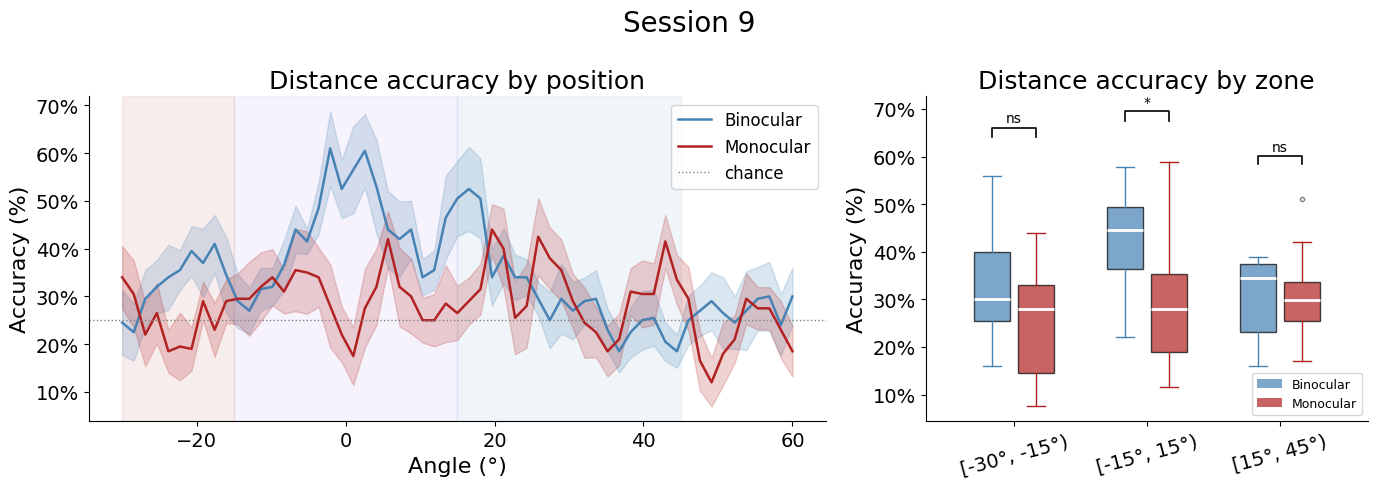

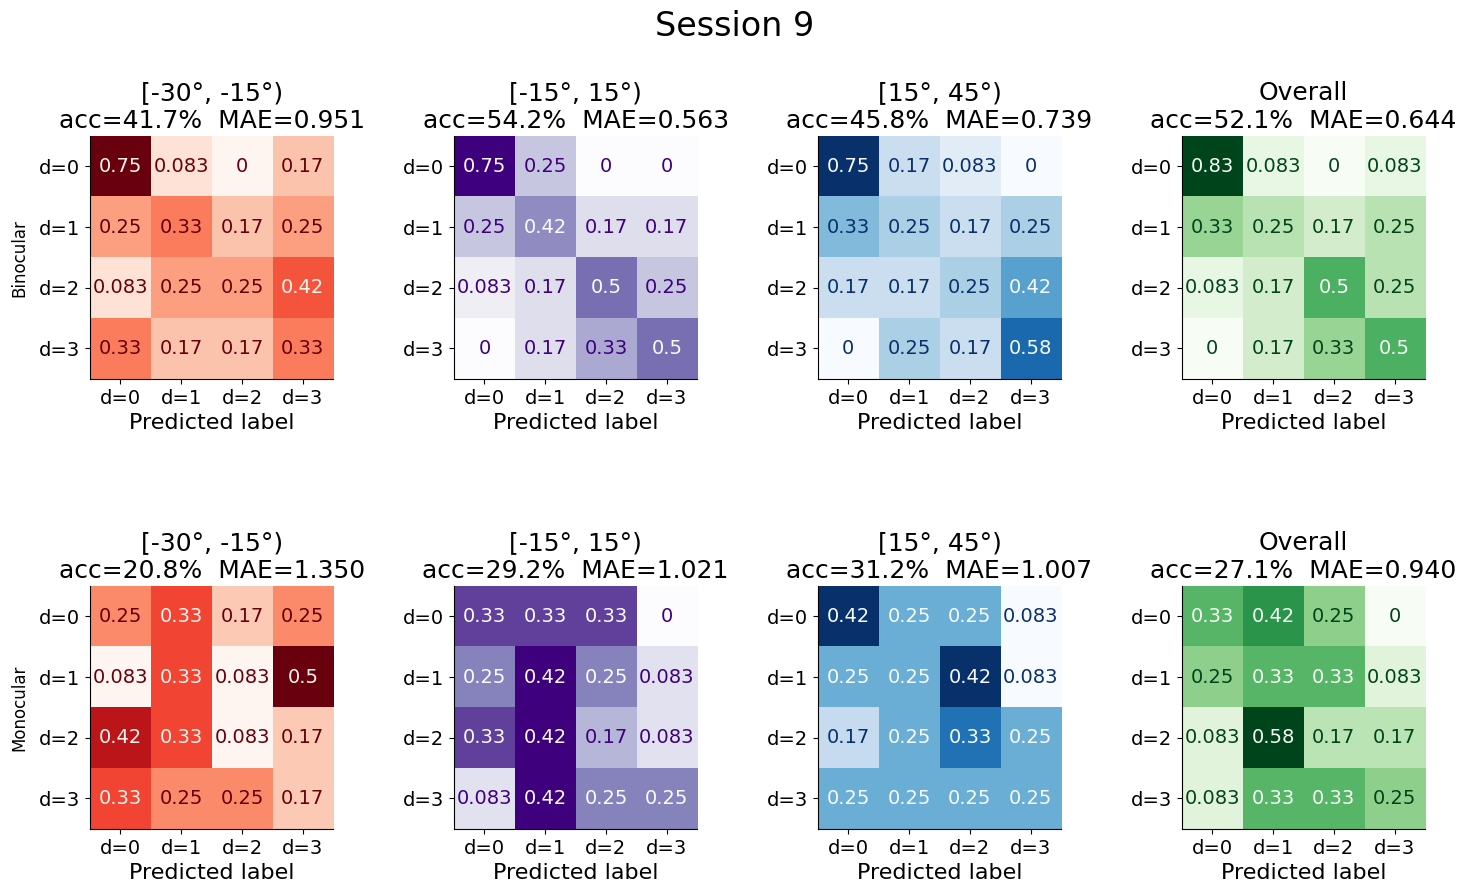

In [29]:
fig = FactoredMLE.plot_distance_comparison(binocular_results, monocular_results, title='Session 9')
fig = FactoredMLE.plot_confusion_by_angle_range([binocular_results, monocular_results], labels=['Binocular', 'Monocular'], title='Session 9')

In [86]:
def plot_area_session_comparison(bino_by_area, mono_by_area,
                                  metric='accuracy', title='',
                                  area_colors=None):
    """
    Two subplots (Binocular | Monocular).
    Within each: one box per area per angle range, individual session means as dots.

    Parameters
    ----------
    bino_by_area : dict  {area_name: [res, res, ...]}
        Lists of FactoredMLE.cross_validate_single_trial results, one per session.
    mono_by_area : dict  same for monocular.
    metric       : 'accuracy' (default) or 'mae'
    title        : str
    area_colors  : dict {area: color} or None
    """
    from matplotlib.patches import Patch

    _default_colors = ['steelblue', 'firebrick', 'seagreen', 'darkorange', 'mediumpurple']
    areas = list(bino_by_area.keys())
    if area_colors is None:
        area_colors = {a: _default_colors[i % len(_default_colors)] for i, a in enumerate(areas)}

    first_res  = next(r for rlist in bino_by_area.values() for r in rlist)
    range_keys = list(first_res['range_results'].keys())
    n_ranges   = len(range_keys)
    n_areas    = len(areas)
    width      = 0.6 / n_areas
    offsets    = np.linspace(-(n_areas - 1) / 2, (n_areas - 1) / 2, n_areas) * width
    x_ticks    = np.arange(1, n_ranges + 1)

    def _fold_metric(res, rname):
        """Per-fold accuracy (%) or MAE for a given angle range."""
        angle_by  = res['angle_by']
        repeat_by = res['repeat_by']
        d_h       = res['d_pred_hard_by_angle']
        d_t       = res['d_true_by_angle']
        deg_axis  = res['deg_axis']
        distances = res['distances']
        folds     = np.unique(repeat_by)

        lo_str, hi_str = rname[1:-1].replace('°', '').split(', ')
        lo, hi     = float(lo_str), float(hi_str)
        range_mask = (deg_axis[angle_by] >= lo) & (deg_axis[angle_by] < hi)

        if metric == 'accuracy':
            return np.array([
                (d_h[(repeat_by == f) & range_mask] == d_t[(repeat_by == f) & range_mask]).mean() * 100
                for f in folds if ((repeat_by == f) & range_mask).any()
            ])
        else:
            d_c = res['d_pred_cont_by_angle']
            return np.array([
                np.abs(d_c[(repeat_by == f) & range_mask]
                       - distances[d_t[(repeat_by == f) & range_mask]]).mean()
                for f in folds if ((repeat_by == f) & range_mask).any()
            ])

    range_bg = ['firebrick', 'mediumpurple', 'steelblue']

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

    for ax, (cond_label, results_by_area) in zip(axes, [
        ('Binocular', bino_by_area),
        ('Monocular', mono_by_area),
    ]):
        for ai, area in enumerate(areas):
            color   = area_colors[area]
            results = results_by_area.get(area, [])
            if not results:
                continue

            for ri, rname in enumerate(range_keys):
                x = x_ticks[ri] + offsets[ai]

                # box = distribution of per-fold values pooled across sessions
                all_folds = np.concatenate([_fold_metric(r, rname) for r in results])
                bp = ax.boxplot(all_folds, positions=[x], widths=width * 0.85,
                                patch_artist=True,
                                medianprops=dict(color='white', linewidth=2),
                                whiskerprops=dict(color=color),
                                capprops=dict(color=color),
                                flierprops=dict(marker='o', markersize=3, color=color, alpha=0.4))
                bp['boxes'][0].set(facecolor=color, alpha=0.6)

                # individual session means as jittered dots
                session_means = [_fold_metric(r, rname).mean() for r in results]
                jitter = np.linspace(-width * 0.15, width * 0.15, len(session_means))
                ax.scatter([x + j for j in jitter], session_means,
                           color=color, s=40, zorder=5, edgecolors='white', linewidths=0.6)

        # range background shading
        for ri, rname in enumerate(range_keys):
            ax.axvspan(x_ticks[ri] - 0.45, x_ticks[ri] + 0.45,
                       color=range_bg[ri % len(range_bg)], alpha=0.07, zorder=0)

        if metric == 'accuracy':
            ax.axhline(25, color='gray', linestyle=':', linewidth=1)
            ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0f}%'))
            ax.set(ylabel='Accuracy (%)', ylim=(0, 100))
        else:
            ax.set(ylabel='Distance MAE', ylim=(0, 100))

        ax.set_xticks(x_ticks)
        ax.set_xticklabels(range_keys, rotation=15)
        ax.set_title(cond_label, fontsize=13)
        ax.set_xlabel('Angle range')
        ax.legend(handles=[Patch(facecolor=area_colors[a], alpha=0.7, label=a) for a in areas],
                  fontsize=9)

    if title:
        fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    return fig


── Session 1 ──────────────────────
  Angle MAE:    9.22°
  Angle RMSE:   14.86°
  Correlation:  0.859
  R²:           0.684
  Dist MAE:     0.85 cm
  Dist Acc:     33.3%
  Angle MAE:    10.65°
  Angle RMSE:   15.76°
  Correlation:  0.836
  R²:           0.644
  Dist MAE:     0.65 cm
  Dist Acc:     45.8%

── Session 2 ──────────────────────
  Angle MAE:    6.69°
  Angle RMSE:   17.00°
  Correlation:  0.814
  R²:           0.586
  Dist MAE:     0.40 cm
  Dist Acc:     64.6%
  Angle MAE:    8.55°
  Angle RMSE:   17.54°
  Correlation:  0.814
  R²:           0.559
  Dist MAE:     0.55 cm
  Dist Acc:     54.2%

── Session 3 ──────────────────────
  Angle MAE:    4.24°
  Angle RMSE:   8.13°
  Correlation:  0.957
  R²:           0.905
  Dist MAE:     0.22 cm
  Dist Acc:     79.2%
  Angle MAE:    7.68°
  Angle RMSE:   17.79°
  Correlation:  0.800
  R²:           0.547
  Dist MAE:     0.58 cm
  Dist Acc:     45.8%

── Session 5 ──────────────────────
  Angle MAE:    5.98°
  Angle RMSE:   12.8

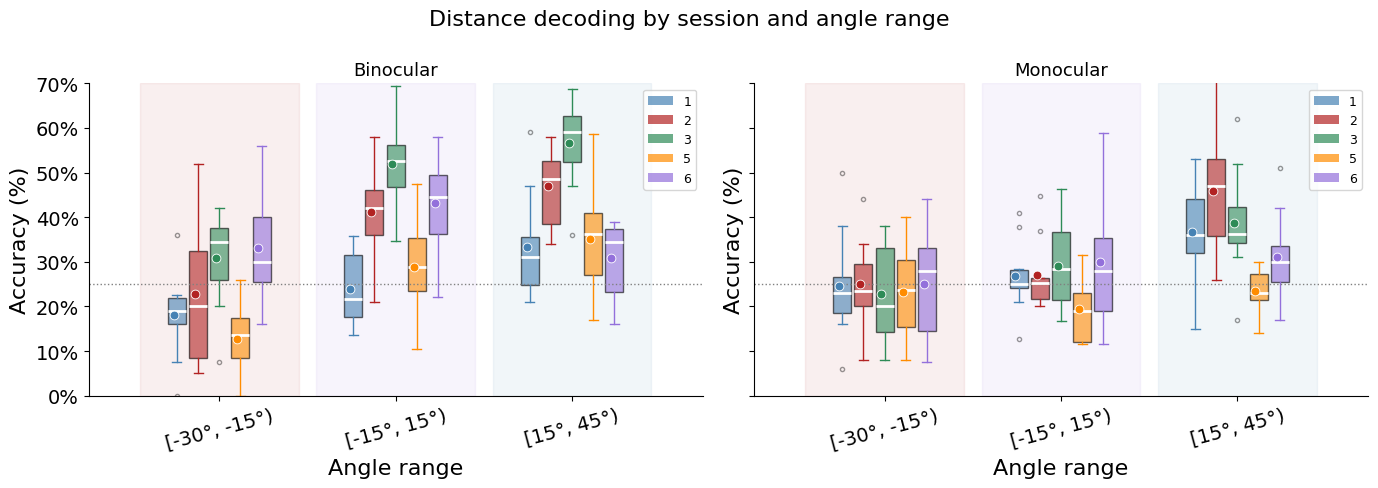

In [47]:
# ── Session decoding ─────────────────────────────────────────────────────────
sessions = [1, 2, 3, 5, 6]

bino_by_session = {}
mono_by_session = {}

for session_id in sessions:
    print(f'\n── Session {session_id} ──────────────────────')
    bino_by_session[session_id] = FactoredMLE.cross_validate_single_trial(
        agg, monocular=0, session=session_id, n_folds=10)
    mono_by_session[session_id] = FactoredMLE.cross_validate_single_trial(
        agg, monocular=1, session=session_id, n_folds=10)

# ── Group by session (each session = its own "area" label) ───────────────────
bino_by_session_wrapped = {str(sid): [res] for sid, res in bino_by_session.items()}
mono_by_session_wrapped = {str(sid): [res] for sid, res in mono_by_session.items()}

# ── Plot ──────────────────────────────────────────────────────────────────────
fig = plot_area_session_comparison(
    bino_by_session_wrapped, mono_by_session_wrapped,
    metric='accuracy',
    title='Distance decoding by session and angle range',
)
plt.show()



── Area V1 ──────────────────────

  Angle MAE:    1.07°
  Dist MAE:     0.39 cm
  Dist Acc:     65.6%

  Angle MAE:    1.27°
  Dist MAE:     0.69 cm
  Dist Acc:     42.6%

── Area LM ──────────────────────

  Angle MAE:    1.67°
  Dist MAE:     0.69 cm
  Dist Acc:     44.0%

  Angle MAE:    11.55°
  Dist MAE:     1.05 cm
  Dist Acc:     26.3%

── Area RL ──────────────────────

  Angle MAE:    1.66°
  Dist MAE:     0.77 cm
  Dist Acc:     37.6%

  Angle MAE:    2.80°
  Dist MAE:     1.12 cm
  Dist Acc:     21.6%


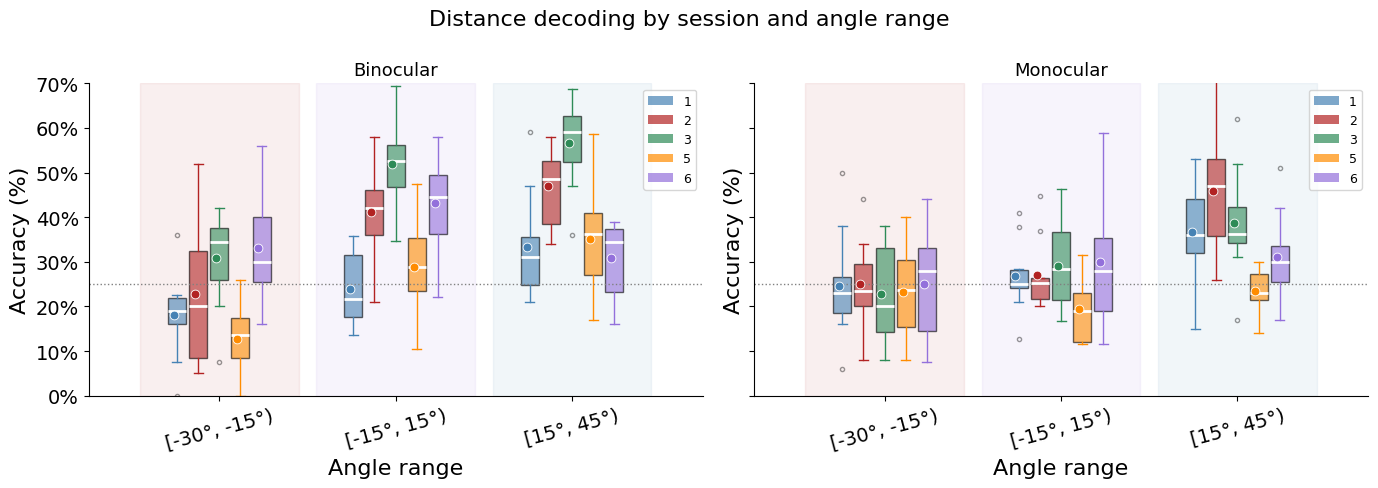

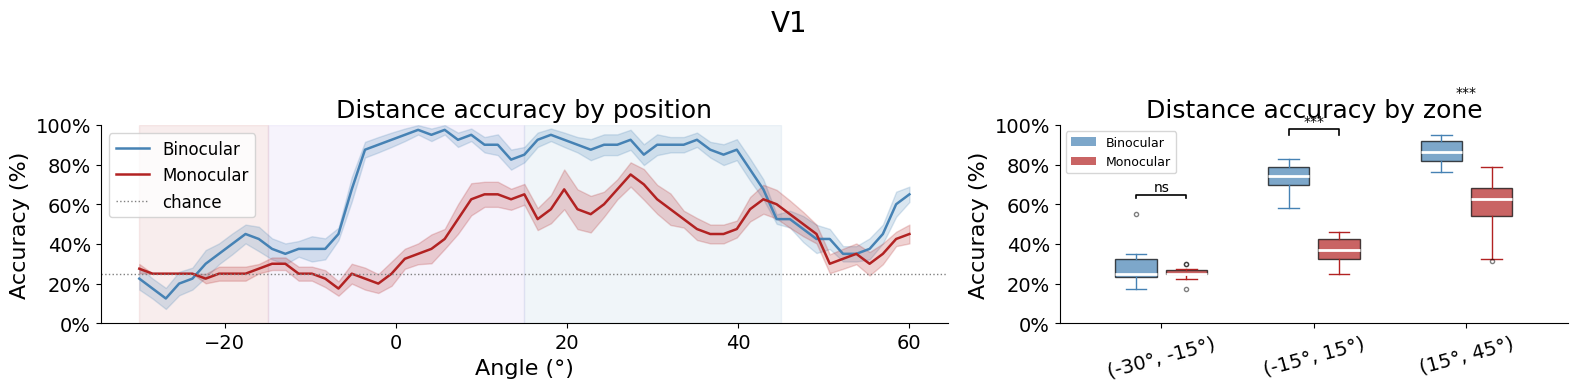

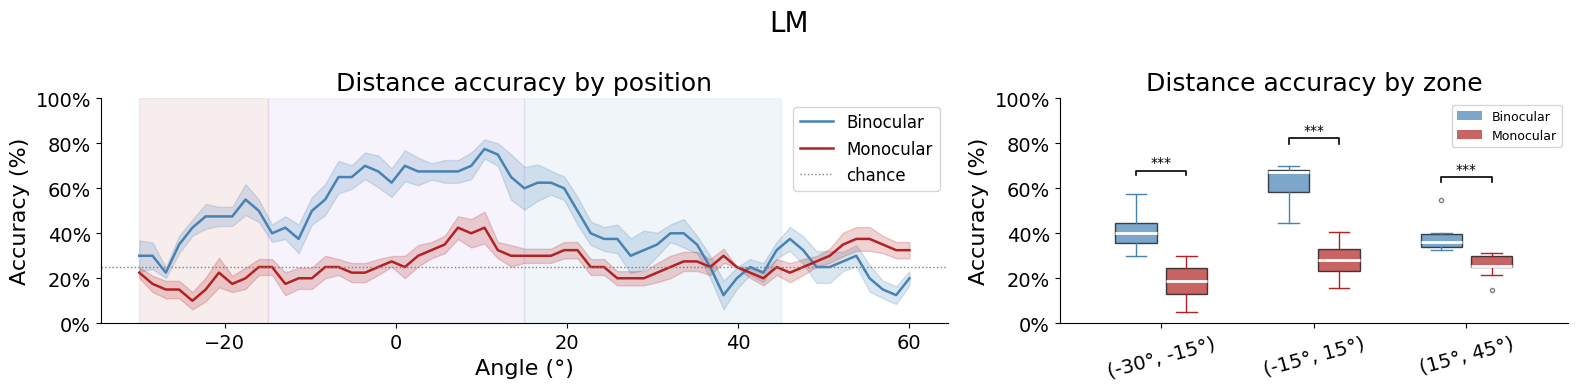

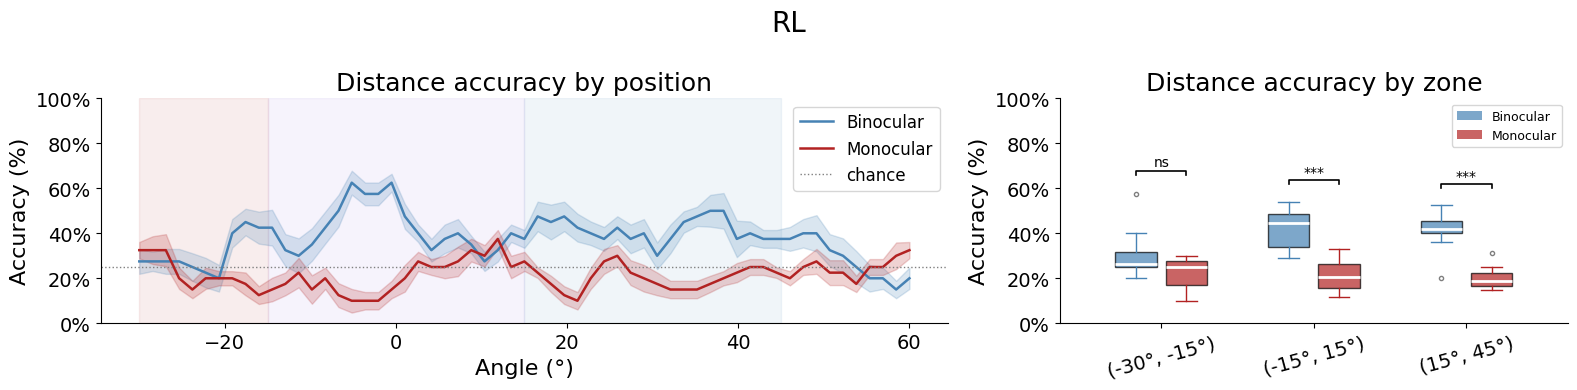

In [ ]:
# ── Session decoding ─────────────────────────────────────────────────────────
areas = ['V1', 'LM', 'RL']

bino_by_area = {}
mono_by_area = {}

for area in areas:
    print(f'\n── Area {area} ──────────────────────')
    bino_by_area[area] = FactoredMLE.cross_validate_averaged(
        agg, monocular=0, area=area)
    mono_by_area[area] = FactoredMLE.cross_validate_averaged(
        agg, monocular=1, area=area)


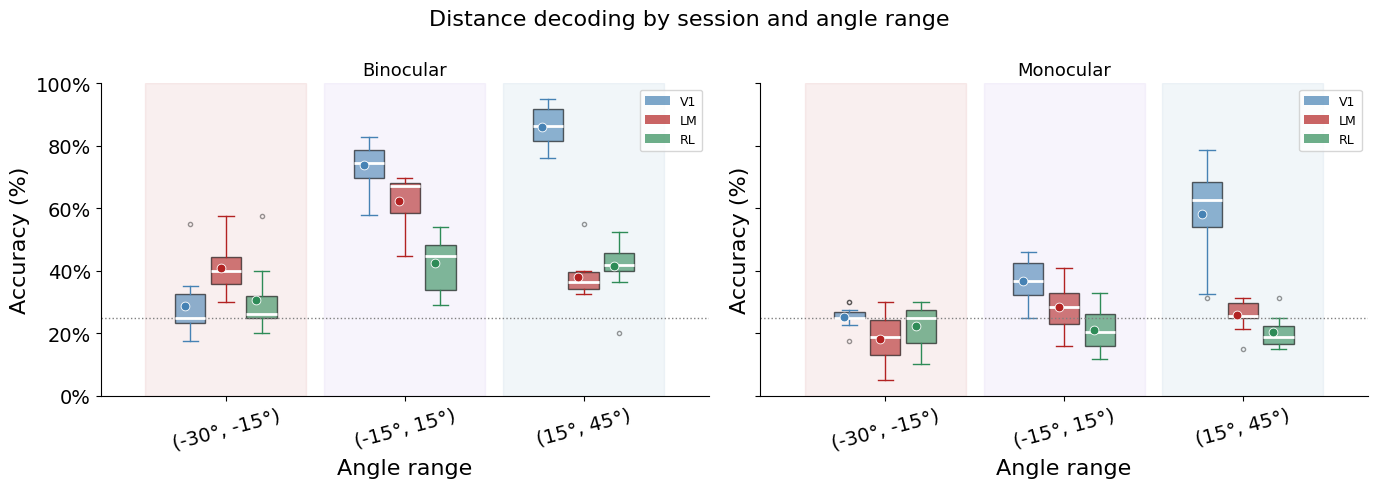

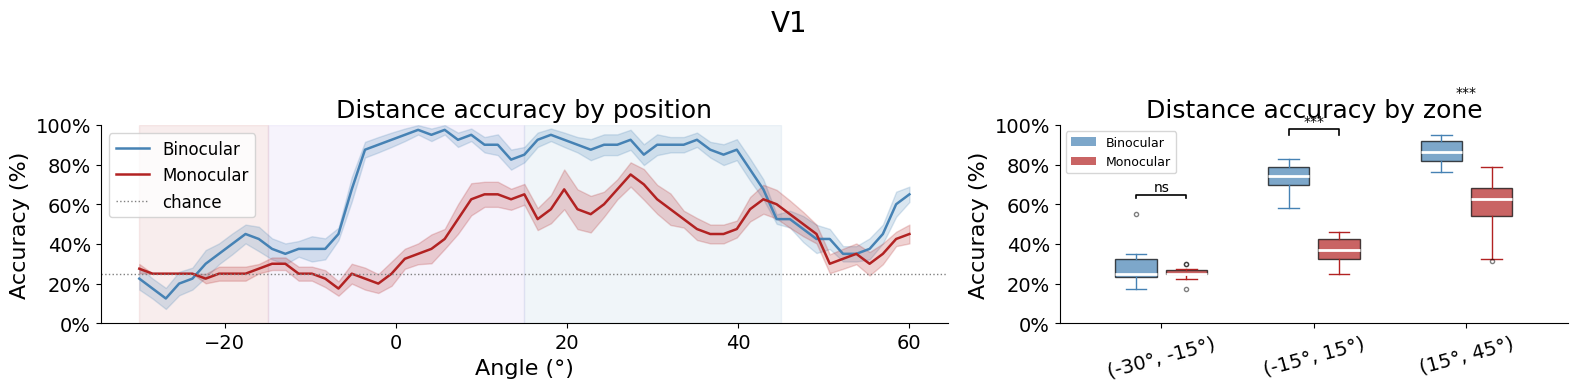

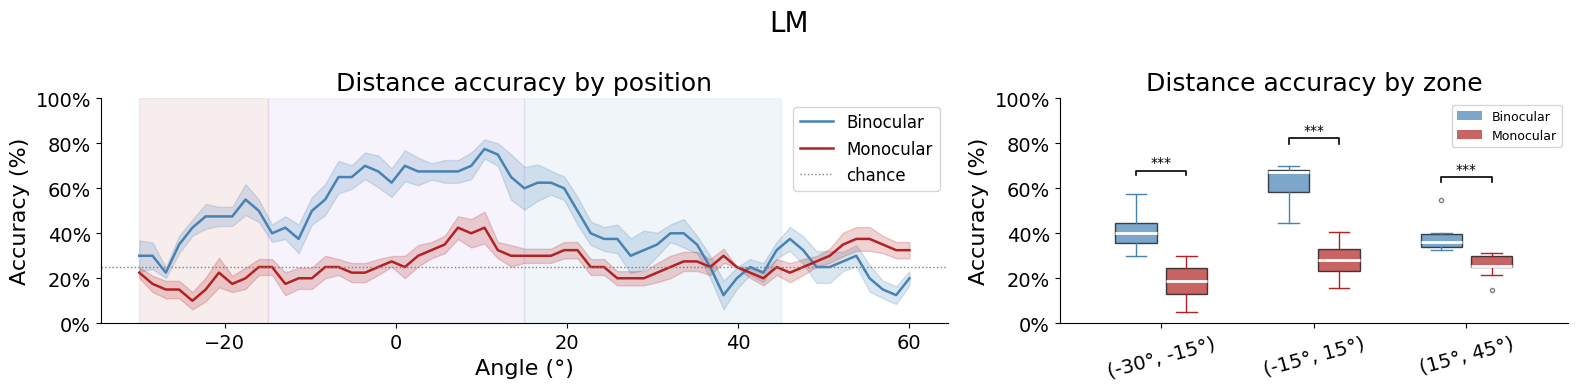

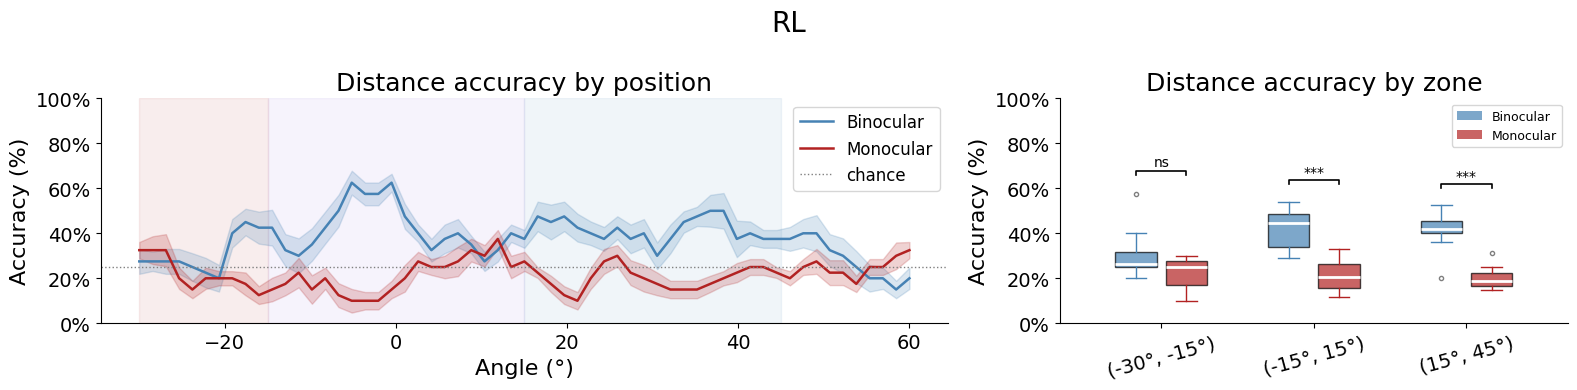

In [87]:
# ── Group by session (each session = its own "area" label) ───────────────────
bino_by_area_wrapped = {str(sid): [res] for sid, res in bino_by_area.items()}
mono_by_area_wrapped = {str(sid): [res] for sid, res in mono_by_area.items()}

# ── Plot ──────────────────────────────────────────────────────────────────────
fig = plot_area_session_comparison(
    bino_by_area_wrapped, mono_by_area_wrapped,
    metric='accuracy',
    title='Distance decoding by session and angle range',
)
plt.show()

for area in areas:
    fig = FactoredMLE.plot_distance_comparison(bino_by_area[area], mono_by_area[area], area)

In [78]:
import numpy as np
import matplotlib.pyplot as plt

def plot_trial_frame(X, trial_id, angle_idx, y_distance, distance_levels, deg_axis, ax=None):
    n_neurons, n_angles, n_trials = X.shape
    n_dist = len(distance_levels)

    # LOO fit
    train_idx = np.delete(np.arange(n_trials), trial_id)
    templates = np.zeros((n_neurons, n_angles, n_dist))
    for i, d_val in enumerate(distance_levels):
        mask = y_distance[train_idx] == d_val
        if mask.any():
            templates[:, :, i] = X[:, :, train_idx[mask]].mean(axis=2)

    dec = FactoredMLE().fit(templates)
    pred_pos, pred_d, scores = dec.decode(X[:, angle_idx, trial_id])

    ll = scores - scores.max()

    true_d_idx = int(np.searchsorted(distance_levels, y_distance[trial_id]))

    theta       = np.deg2rad(deg_axis)
    dtheta      = theta[1] - theta[0]
    theta_edges = np.append(theta - dtheta / 2, theta[-1] + dtheta / 2)
    r_edges     = np.arange(n_dist + 1)

    if ax is None:
        fig, ax = plt.subplots(subplot_kw=dict(projection='polar'), figsize=(7, 6))
    else:
        fig = ax.figure

    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)

    mesh = ax.pcolormesh(theta_edges, r_edges, ll.T, cmap='hot', shading='flat', vmin=ll.min())

    ax.set_thetamin(deg_axis[0])
    ax.set_thetamax(deg_axis[-1])

    ax.plot(np.deg2rad(deg_axis[angle_idx]), true_d_idx + 0.5,
            'c*', markersize=18, zorder=5, label='True')
    ax.plot(np.deg2rad(deg_axis[pred_pos]),  pred_d + 0.5,
            'b^', markersize=14, zorder=5, markeredgecolor='white', markeredgewidth=1.5,
            label='Decoded')

    ax.set_rticks(np.arange(n_dist) + 0.5)
    ax.set_yticklabels([f'{d:.0f} cm' for d in distance_levels])
    ax.set_rlabel_position(deg_axis[-1] + 3)
    ax.set_thetagrids(np.linspace(deg_axis[0], deg_axis[-1], 6).round())

    ax.set_title(
        f'Trial {trial_id}  ·  pos {deg_axis[angle_idx]:.0f}°  ·  true dist {distance_levels[true_d_idx]:.0f} cm',
        pad=20
    )
    ax.legend(loc='upper left', bbox_to_anchor=(-0.2, 1.1), framealpha=0.5)
    plt.colorbar(mesh, ax=ax, label='log-likelihood (relative to max)', shrink=0.7, pad=0.1)

    return fig, ax


[ok] Loaded aggregated traces from cache


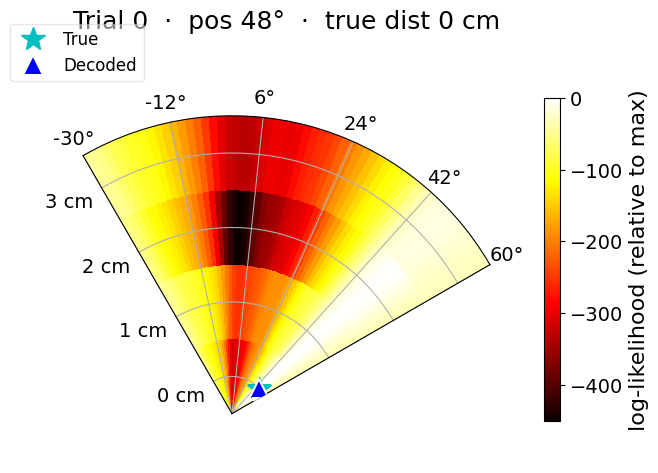

In [ ]:
# Get data the same way the CV function does
agg = SessionAggregator(
    mouse_name=MOUSE,
    experiment_name=EXPERIMENT
)
X, y_distance = agg.get_decoder_data(monocular=0, area=None, session=3)  # adjust monocular/area as needed
distance_levels = agg.distances   # (n_distances,)
deg_axis        = agg.angle_axis  # (n_angles,)

# Then plot trial 0 at angle position 5
fig, ax = plot_trial_frame(X, trial_id=0, angle_idx=0,
                           y_distance=y_distance,
                           distance_levels=distance_levels,
                           deg_axis=deg_axis)
plt.show()


C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_754728\1664919500.py:77: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


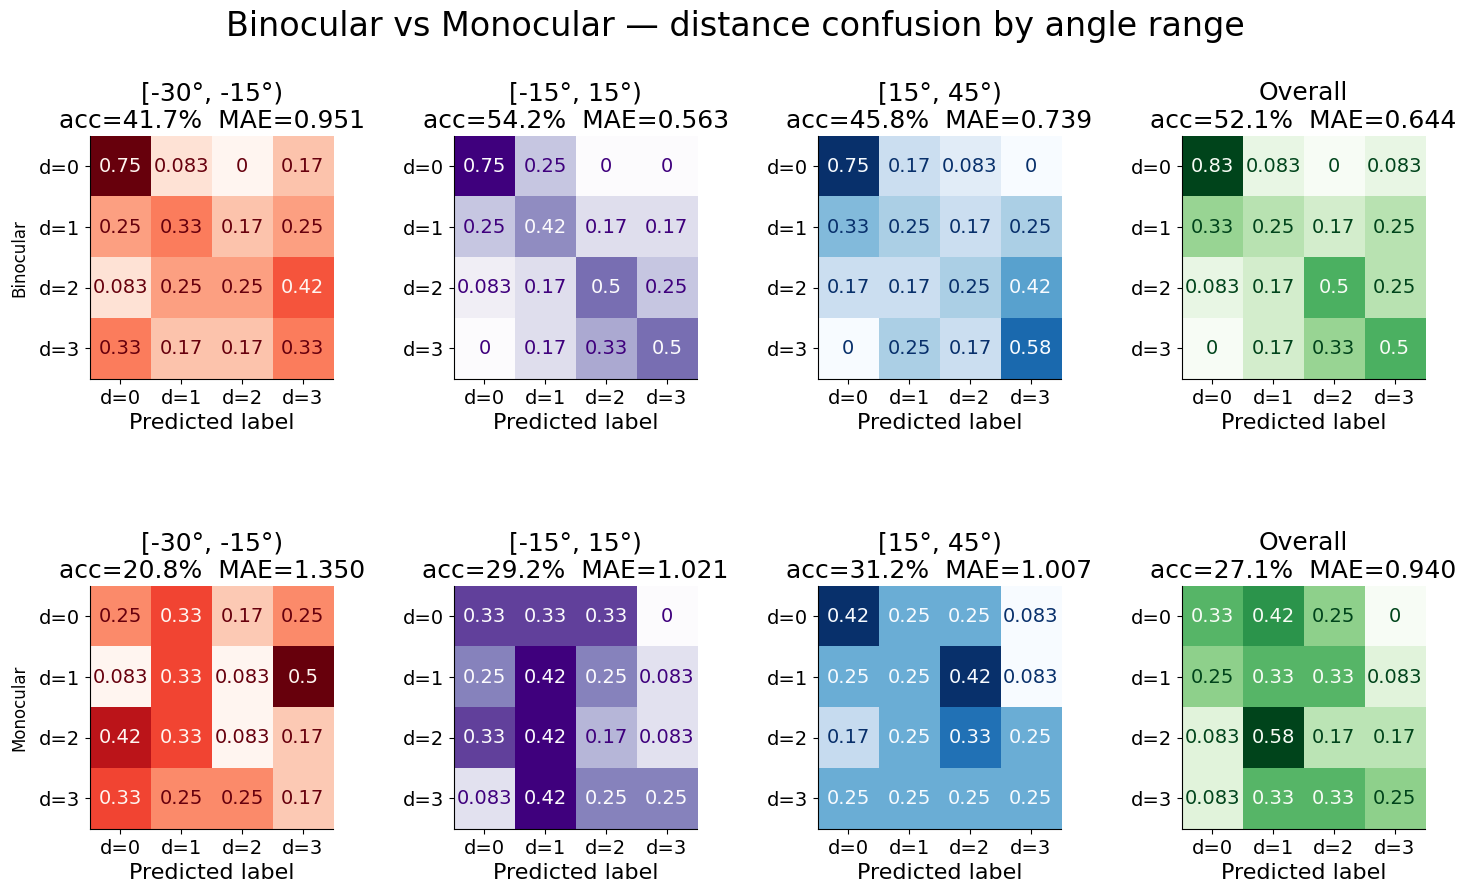

In [ ]:
def plot_confusion_by_angle_range(results, labels=None, title=''):
    """
    Grid of confusion matrices.

    Layout:
      rows  — one per result set
      col 0 — Left eye range   (Reds)
      col 1 — Both eyes range  (Purples)
      col 2 — Right eye range  (Blues)
      col 3 — Overall, all angles pooled (Greens)

    Parameters
    ----------
    results : dict or list of dict
        Output of FactoredMLE.cross_validate_single_trial.
    labels  : str or list of str, optional
    title   : str, optional
    """
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

    if isinstance(results, dict):
        results = [results]
    if labels is None:
        labels = [f'Result {i+1}' for i in range(len(results))]
    elif isinstance(labels, str):
        labels = [labels]

    range_keys = list(results[0]['range_results'].keys())
    n_ranges   = len(range_keys)
    n_rows     = len(results)
    n_cols     = n_ranges + 1   # ranges first, overall last

    range_cmaps = ['Reds', 'Purples', 'Blues', 'Oranges']  # one per range

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(4.5 * n_cols, 4.5 * n_rows),
        squeeze=False,
        gridspec_kw={'hspace':0.85}  # add vertical space between rows
    )

    for r, (res, label) in enumerate(zip(results, labels)):
        distances   = res['distances']
        n_dist      = len(distances)
        dist_labels = [f'd={d}' for d in distances]

        # ── col 0…n_ranges-1: one per angle range ───────────────────────────
        for c, rname in enumerate(range_keys):
            ax   = axes[r, c]
            rres = res['range_results'][rname]
            cm   = confusion_matrix(rres['d_true'], rres['d_pred_hard'],
                                    labels=list(range(n_dist)), normalize='true')
            ConfusionMatrixDisplay(cm, display_labels=dist_labels).plot(
                ax=ax, colorbar=False, cmap=range_cmaps[c % len(range_cmaps)])
            acc_r = rres.get('dist_acc', np.nan)
            mae_r = rres.get('dist_mae_cont', np.nan)
            ax.set_title(f'{rname}\nacc={acc_r*100:.1f}%  MAE={mae_r:.3f}')
            if c == 0:
                ax.set_ylabel(label, fontsize=12, labelpad=8)
            else:
                ax.set_ylabel('')

        # ── last col: overall (all angles pooled) ───────────────────────────
        ax  = axes[r, -1]
        cm  = confusion_matrix(res['d_true'], res['d_pred_hard'],
                               labels=list(range(n_dist)), normalize='true')
        ConfusionMatrixDisplay(cm, display_labels=dist_labels).plot(
            ax=ax, colorbar=False, cmap='Greens')
        acc = (np.array(res['d_pred_hard']) == np.array(res['d_true'])).mean()
        mae = np.abs(np.array(res['d_pred_cont'])
                     - distances[np.array(res['d_true'])]).mean()
        ax.set_title(f'Overall\nacc={acc*100:.1f}%  MAE={mae:.3f}')
        ax.set_ylabel('')

    if title:
        fig.suptitle(title, fontsize=24, y=1.02)
    plt.tight_layout()
    return fig



  Angle MAE:    1.06°
  Dist MAE:     0.36 cm
  Dist Acc:     67.8%

  Angle MAE:    1.23°
  Dist MAE:     0.69 cm
  Dist Acc:     42.4%


In [82]:

areas = ['V1', 'LM', 'RL']

for area in areas:
    binocular_results = FactoredMLE.cross_validate_averaged(agg, monocular=0, area=area)
    monocular_results = FactoredMLE.cross_validate_averaged(agg, monocular=1, area=area)
    figure = FactoredMLE.plot_distance_comparison(binocular_results, monocular_results, area)

KeyboardInterrupt: 